#### Data cleaning steps :

1. Understanding the data
2. check missing value
3. Remove duplicate Records
4. Fix Data type
5. Handle Outliers
6. Standrized Text like : "Male,MALE,MAle,  male   --> to male" using `.str.lower()` and `.str.strip()`
7. Handle incorrect values --> age = 0 not possible fix it
8. Encoding Categorical Data
9. Apply feature scalling (if Required)

#### Code Example :

In [230]:
# Import library
import pandas as pd
import numba as np
import matplotlib.pyplot as plt
import seaborn as sns

In [231]:
# Load Data
df = pd.read_csv('netflix_titles.csv')


In [232]:
# print 
df.head(2)

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."


In [233]:
# Check info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [234]:
# Check shape
df.shape

(8807, 12)

In [235]:
# Check all columns
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='object')

In [236]:
### Handle Missing Values
# Detect missing value
df.isnull().sum()

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [237]:
# Fill missing value
df['director'] = df['director'].fillna(df['director'].mode()[0])
df['cast'] = df['cast'].fillna(df['cast'].mode()[0])
df['country'] = df['country'].fillna(df['country'].mode()[0])
df['director'] = df['director'].fillna(df['director'].mode()[0])
df['date_added'] = df['date_added'].fillna(df['date_added'].mode()[0])
df['rating'] = df['rating'].fillna(df['rating'].mode()[0])
df['duration'] = df['duration'].fillna(df['duration'].mode()[0])


In [238]:
# No duplicate columns
df.duplicated().sum()

np.int64(0)

In [239]:
### Fix Data Types...
df['show_id'] = df['show_id'].str.replace('s','')
df['show_id'] = df['show_id'].astype('int64')


In [240]:
df['date_added'] = pd.to_datetime(df['date_added'],format='mixed')
df['Day_added'] = pd.to_datetime(df['date_added'],format='mixed').dt.day
df['Month_added'] = pd.to_datetime(df['date_added'],format='mixed').dt.month
df['year_added'] = pd.to_datetime(df['date_added'],format='mixed').dt.year

In [241]:
df.drop('date_added',axis=1,inplace=True)

In [242]:
df['duration'] = df['duration'].str.replace('min','')
df['duration'] = df['duration'].str.replace('Seasons','')
df['duration'] = df['duration'].str.replace('Season','')

In [243]:
df['duration'] = df['duration'].astype('int64')

In [244]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   int64 
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      8807 non-null   object
 4   cast          8807 non-null   object
 5   country       8807 non-null   object
 6   release_year  8807 non-null   int64 
 7   rating        8807 non-null   object
 8   duration      8807 non-null   int64 
 9   listed_in     8807 non-null   object
 10  description   8807 non-null   object
 11  Day_added     8807 non-null   int32 
 12  Month_added   8807 non-null   int32 
 13  year_added    8807 non-null   int32 
dtypes: int32(3), int64(3), object(8)
memory usage: 860.2+ KB


In [245]:
# Remove Useless Columns
df.drop('description',axis=1,inplace=True)

Outliers Remove

<Axes: >

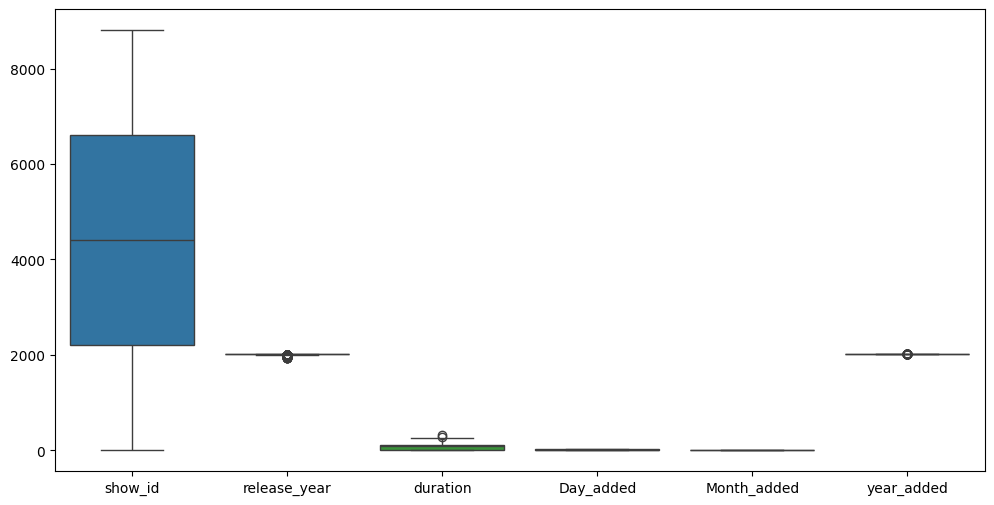

In [246]:
plt.figure(figsize=(12,6))
num_col = df.select_dtypes(include=['int64','float64','int32'])
sns.boxplot(num_col)

In [247]:
# IQR method
Q1 = df['release_year'].quantile(0.25)
Q3 = df['release_year'].quantile(0.75)
IQR = Q3 - Q1

# Filter the data: outliers remove
df = df[~((df['release_year'] < (Q1 - 1.5 * IQR)) | (df['release_year'] > (Q3 + 1.5 * IQR)))]

In [248]:
# IQR method
Q1 = df['duration'].quantile(0.25)
Q3 = df['duration'].quantile(0.75)
IQR = Q3 - Q1

# Filter the data: outliers remove
df = df[~((df['duration'] < (Q1 - 1.5 * IQR)) | (df['duration'] > (Q3 + 1.5 * IQR)))]

In [249]:
# IQR method
Q1 = df['year_added'].quantile(0.25)
Q3 = df['year_added'].quantile(0.75)
IQR = Q3 - Q1

# Filter the data: outliers remove
df = df[~((df['year_added'] < (Q1 - 1.5 * IQR)) | (df['year_added'] > (Q3 + 1.5 * IQR)))]

Standrized Text

In [250]:
object_col = df.select_dtypes(include=['object'])
for col in object_col:
    df[col] = df[col].str.lower()
df[col] = df[col].str.strip()

In [251]:
### No detect incorrect values

In [252]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8046 entries, 0 to 8806
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8046 non-null   int64 
 1   type          8046 non-null   object
 2   title         8046 non-null   object
 3   director      8046 non-null   object
 4   cast          8046 non-null   object
 5   country       8046 non-null   object
 6   release_year  8046 non-null   int64 
 7   rating        8046 non-null   object
 8   duration      8046 non-null   int64 
 9   listed_in     8046 non-null   object
 10  Day_added     8046 non-null   int32 
 11  Month_added   8046 non-null   int32 
 12  year_added    8046 non-null   int32 
dtypes: int32(3), int64(3), object(7)
memory usage: 785.7+ KB


Categorical to numerical

In [256]:
from sklearn.preprocessing import LabelEncoder
object_col = df.select_dtypes(include=['object'])
for col in object_col:
    encoder = LabelEncoder()
    df[f'num_{col}'] = encoder.fit_transform(df[col])


In [257]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8046 entries, 0 to 8806
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   show_id        8046 non-null   int64 
 1   type           8046 non-null   object
 2   title          8046 non-null   object
 3   director       8046 non-null   object
 4   cast           8046 non-null   object
 5   country        8046 non-null   object
 6   release_year   8046 non-null   int64 
 7   rating         8046 non-null   object
 8   duration       8046 non-null   int64 
 9   listed_in      8046 non-null   object
 10  Day_added      8046 non-null   int32 
 11  Month_added    8046 non-null   int32 
 12  year_added     8046 non-null   int32 
 13  num_type       8046 non-null   int64 
 14  num_title      8046 non-null   int64 
 15  num_director   8046 non-null   int64 
 16  num_cast       8046 non-null   int64 
 17  num_country    8046 non-null   int64 
 18  num_rating     8046 non-null   in

In [287]:
df[['country','num_country']]

,country,num_country
0,united states,571
1,south africa,404
2,united states,571
3,united states,571
4,india,240
...,...,...
8802,united states,571
8803,united states,571
8804,united states,571
8805,united states,571
